In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# PRÁCTICA 7 "Segmentación de imágenes: aplicación de la Transformada de Hough”

**Objetivo**: Comprensión y aplicación de la Transformada de Hough para detectar líneas rectas
y circunferencias en imágenes.  

## PRIMERA PARTE: Segmentación de carreteras mediante la aplicación de la Transformada de Hough para detectar líneas rectas.

**Lectura de imagen y generación de imagen de bordes**

1. Lee la imagen P7_1.tif y genera su imagen de intensidad I utilizando la función de
OpenCV cvtColor con la opción COLOR_BGR2GRAY.

(np.float64(-0.5), np.float64(634.5), np.float64(187.5), np.float64(-0.5))

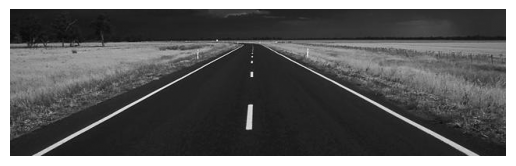

In [2]:
I = cv2.imread("imagenEntrada/PrimeraParte/P7_1.tif")
I = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)

plt.imshow(I, cmap="gray")
plt.axis("off")

2. A partir de I, genera una imagen binaria de bordes Ib aplicando un detector de bordes
verticales de Sobel, basado en considerar únicamente la componente x del vector gradiente.
Para generar una imagen binaria de bordes (Ib) Se debe utilizar como umbral el 30% del
valor máximo de la magnitud del gradiente horizontal. Visualiza la imagen de intensidad I
y la imagen de bordes Ib y describe los distintos pasos metodológicos que se pueden
distinguir para su generación.

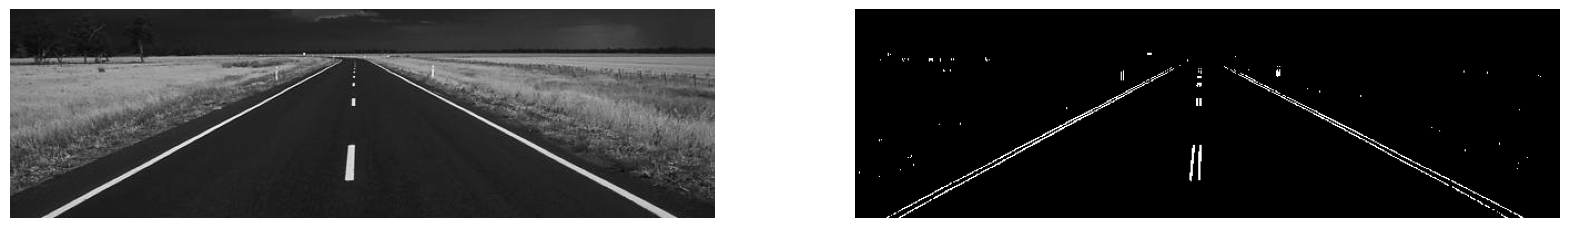

In [3]:
# Generar la matriz con la magnitud del vector gradiente horizontal
Gx = cv2.Sobel(I, cv2.CV_64F, 1, 0, ksize=3, borderType=cv2.BORDER_REPLICATE)
Gx = np.abs(Gx)
# Umbralizar según un criterio
maxi  = np.max(Gx)
umbral = 0.3 * maxi

# Binarizar la imagen con un umbral 
Ib = Gx > umbral

plt.figure(figsize=(20,20))
plt.subplot(1,2,1)
plt.imshow(I, cmap="gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(Ib, cmap="gray")
plt.axis("off")

plt.show()

### **Transformada de Hough para rectas:**

3. Aplica a Ib la Transformada de Hough para detectar líneas rectas utilizando la función
facilitada generar_acumulador_T_H_Rectas:

`H,theta,rho = generar_acumulador_T_H_Rectas (Ib)`

Para entender el procedimiento, se debe tener clara la respuesta a estas preguntas:

- ¿Qué representan theta y rho?

- ¿Cuál es el significado de los valores almacenados en H?

-  ¿Cómo es la discretización que se realiza del espacio de parámetros en esta configuración por defecto de la función?

In [4]:
from Funciones.funciones_Transformada_Hough import generar_acumulador_T_H_Rectas

H, theta, rho = generar_acumulador_T_H_Rectas(Ib)

# theta es el vector de angulos con la normal de la recta con el eje de coordenadas de 0-179
# rho es el vector de distancias de la recta con el eje de coordenadas

# Los valores almacenados en H son el numero de puntos que pasan por una recta definida por la distancia al eje de coordenadas y el angulo de la normal de la distancia.

# La discretizacion de theta es de 0 a 179 con paso de 1 
# La discretizacion de rho es de -662 a 662 de paso de 1
# Esto es así porque la distancias negativas corresponderian a los angulos del tercer y cuarto cuadrante.

### **Recta más votada:**

4. Ayudándote de la función numpy where, encuentra los parámetros de la recta que pasa por
más puntos en la imagen binaria Ib. ¿Por cuántos puntos pasa? Escribe la ecuación de
dicha recta.

In [5]:
x, y = np.where(H == np.max(H))
distancia = int(rho[x][0]) 
angulo = int(theta[y][0])

print(f"Puntos que pasan por la recta: {np.max(H)}")
print(f"Distancia: {distancia}")
print(f"Angulo: {angulo}")

Puntos que pasan por la recta: 210
Distancia: -111
Angulo: 118


5. Utiliza la ecuación de la recta anterior para representarla de las siguientes formas: 

a)  Sobre una imagen de intensidad inicializada en blanco (valor 255) de las mismas
dimensiones que la imagen de intensidad de entrada. Los píxeles de la imagen que
pasen por la recta deben pasar a tener un valor 0 en esa imagen inicializada blanca.

b)  Sobre la imagen binaria Ib en color rojo.


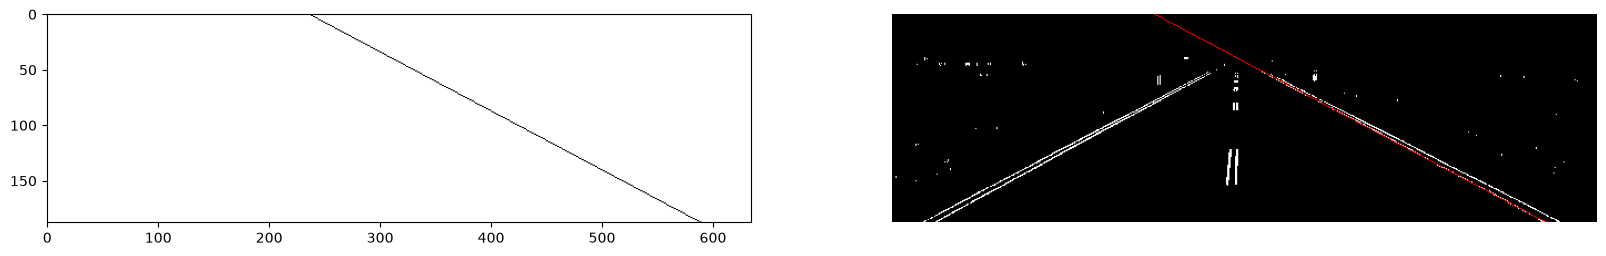

In [6]:
imgBlanco = np.ones_like(Ib, np.uint8) * 255
ibColor = np.stack([Ib, Ib, Ib], axis=-1).astype(np.uint8) * 255
filas, columnas = Ib.shape

if distancia < 0:
    angulo += 180
    distancia = np.abs(distancia)

anguloRad = np.deg2rad(angulo)
s, c = np.sin(anguloRad), np.cos(anguloRad)

if abs(s) > 1e-6:
    recta = np.zeros(columnas, np.float32)
    for x in range(columnas):
        recta[x] = np.round((distancia - x * c) / s)   # recta[x] = y (fila)

    indicesColumnas = np.arange(columnas)
    mascara = (recta >= 0) & (recta < filas)

    columnasValidas = indicesColumnas[mascara]
    filasValidas = recta[mascara].astype(int)

    imgBlanco[filasValidas, columnasValidas] = 0
    ibColor[filasValidas, columnasValidas] = [255, 0, 0]

plt.figure(figsize=(20,10))
plt.subplot(1, 2, 1)
plt.imshow(imgBlanco, cmap="gray")


plt.subplot(1, 2, 2)
plt.imshow(ibColor)
plt.axis("off")
plt.show()

### **Rectas más votadas**

6. Encuentra los parámetros representativos de las 4 rectas más votadas, garantizando que
estas tengan un número de votos mayor que el 50% del número de votos de la recta más
votada. Para ello aplica la función facilitada obtener_rectas_mas_votadas:

`P = obtener_rectas_mas_votadas(H, num_peaks=NumRectas, threshold=Umbral)`

Contesta a las siguientes preguntas:

- ¿Qué información contiene el parámetro de salida P?

- ¿Qué significado tiene el parámetro de entrada Umbral en la función?

- ¿Qué efecto tendría fijar un valor Umbral con un valor que sea el 75% del número
de votos máximo?

In [7]:
from Funciones.funciones_Transformada_Hough import obtener_rectas_mas_votadas

maxi = np.max(H)

P = obtener_rectas_mas_votadas(H, num_peaks=4, threshold=maxi*0.5)
print(P)

# P es un array en el que cada fila representa los valores de la distancia de la recta al origen de coordenadas y el angulo con la normal de la distancia

# El umbral representa el número de pixeles de borde mínimo que debe contener una recta definida por theta y rho 

# Si subes el umbral al 75% tienes un detector de bordes mas estricto, por ello es probable que menos rectas cumplan la condición para ser candidatas.

[[551 118]
 [845  61]
 [556 117]
 [840  63]]


7. Representa en verde el conjunto de las rectas almacenadas en P sobre la imagen de bordes. 

In [8]:
def generar_lineas_en_imagen(I, theta, rho, color):
    I = I.copy()
    filas, columnas = I.shape[:2]
    x = np.arange(columnas)

    if rho < 0:
        theta += 180
        rho = np.abs(rho)

    s = np.sin(np.deg2rad(theta))
    c = np.cos(np.deg2rad(theta))

    # Recta vertical: x = rho / cos(θ)
    if abs(s) < 1e-6:
        xv = int(round(rho / c))
        if 0 <= xv < columnas:
            I[:, xv] = color
        return I

    y = np.round((rho - x * c) / s).astype(int)

    mascara = (y >= 0) & (y < filas)
    I[y[mascara], x[mascara]] = color
    return I

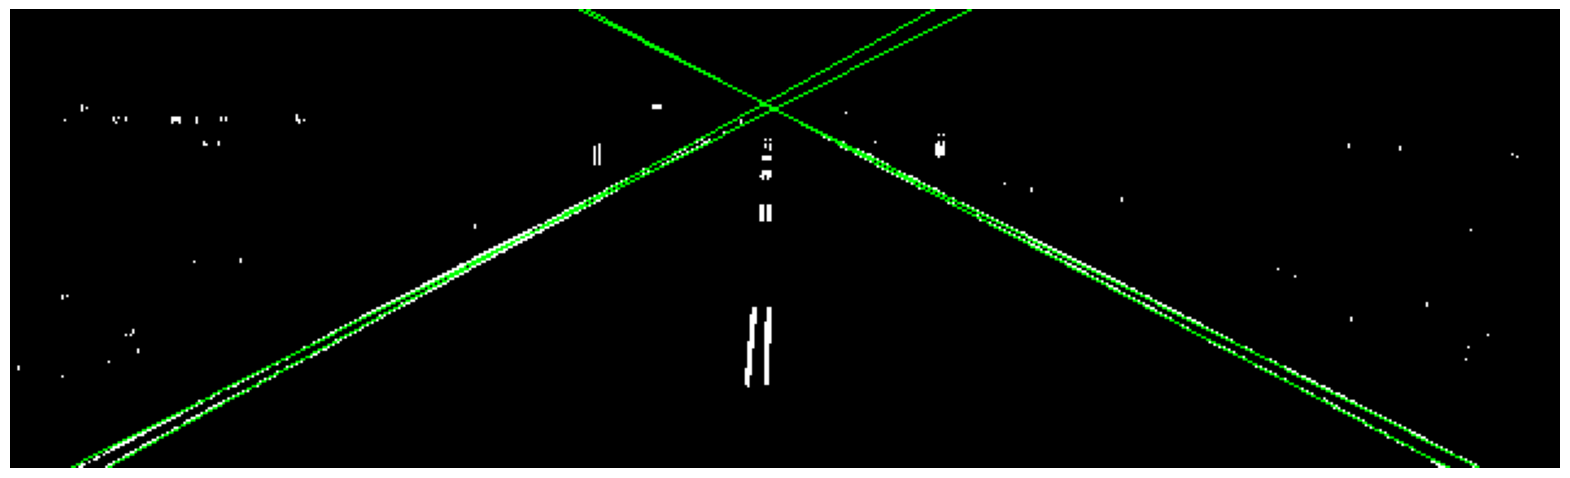

In [9]:
ibColor = np.stack([Ib, Ib, Ib], axis=-1).astype(np.uint8) * 255

for i in range(4):
    ibColor = generar_lineas_en_imagen(ibColor, theta[P[i, 1]], rho[P[i, 0]], [0, 255, 0])   

plt.figure(figsize=(20,10))
plt.imshow(ibColor)
plt.axis("off")
plt.show()


8. Representa en rojo el conjunto de rectas que detecta la función de OpenCV HoughLines:

`rectas = cv2.HoughLines(Ibordes.astype(np.uint8), 1, np.pi/180, Umbral.astype(int))`

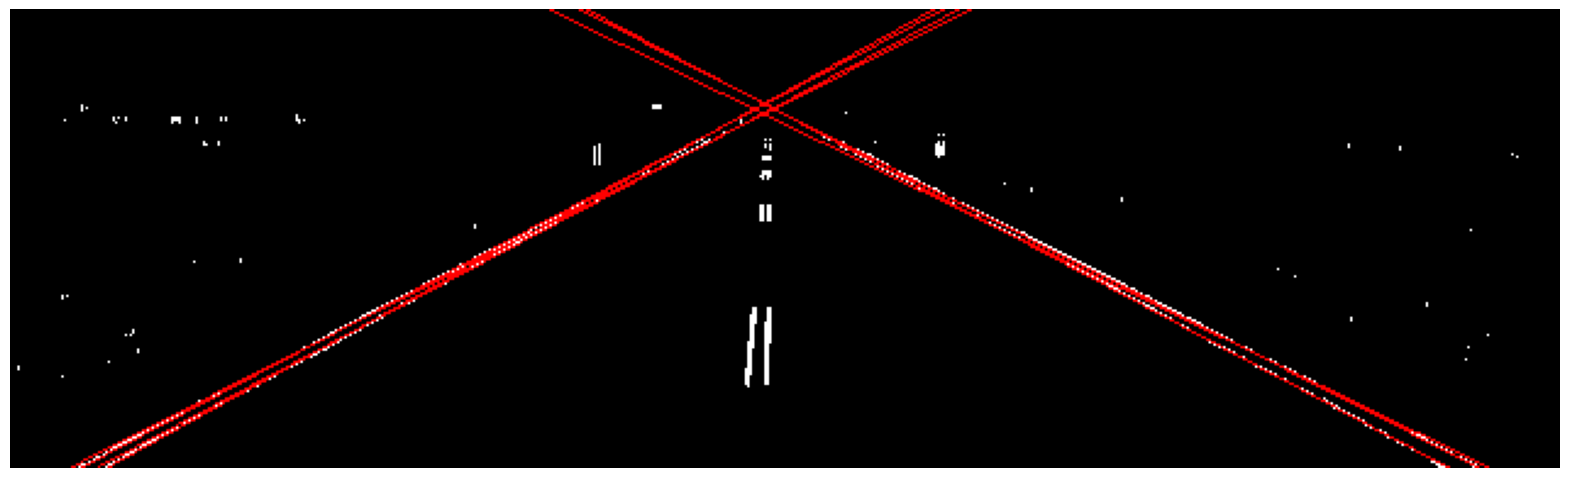

In [10]:
umbral = maxi * 0.5
P = cv2.HoughLines(Ib.astype(np.uint8), 1, np.pi/180, umbral.astype(int))
ibColor = np.stack([Ib, Ib, Ib], axis=-1).astype(np.uint8) * 255
for i in range(P.shape[0]):
    p = P[i][0]
    ibColor = generar_lineas_en_imagen(ibColor, np.rad2deg(p[1]), p[0], [255, 0, 0])

plt.figure(figsize=(20,10))
plt.imshow(ibColor)
plt.axis("off")
plt.show()



### **Segmentación de la carretera**

9. A partir de la información almacenada en P, realiza la segmentación de la carretera
siguiendo los siguientes pasos:

-  Sobre una imagen binaria blanca (matriz uint8 inicializada a 255) de las mismas
dimensiones que la imagen de intensidad original, asigna un valor 0 a todos los píxeles
presentes en las rectas detectadas en P. Visualiza la imagen binaria resultante.

- Aplica un filtro de mínimos 5x5 a la imagen binaria anterior para unir los puntos de las
líneas detectadas y delimitar regiones candidatas a ser la zona principal de la carretera.
Visualiza la imagen binaria resultante.

- Etiqueta la imagen binaria resultante del apartado anterior con la función de OpenCV
connectedComponents.

- Genera y visualiza la imagen binaria que representa la segmentación de la carretera
asumiendo que es la región conectada de píxeles que contiene al píxel central de la
imagen. 

- Visualiza el resultado a través de una imagen que muestre únicamente los valores de
intensidad de los píxeles detectados (el resto de los píxeles se visualizarán en negro).


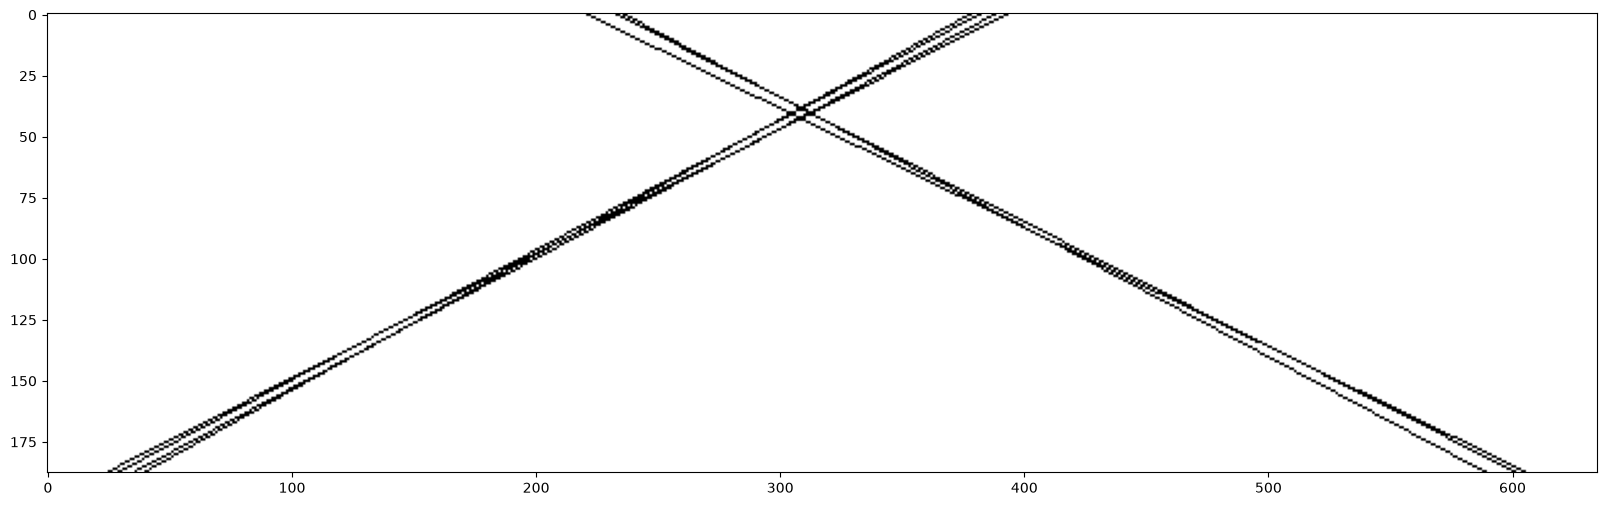

In [11]:
lienzo = np.ones_like(I, dtype=np.uint8) * 255

for i in range(P.shape[0]):
    p = P[i][0]
    lienzo = generar_lineas_en_imagen(lienzo, np.rad2deg(p[1]), p[0], 0)

plt.figure(figsize=(20,10))
plt.imshow(lienzo, cmap="gray")
plt.show()



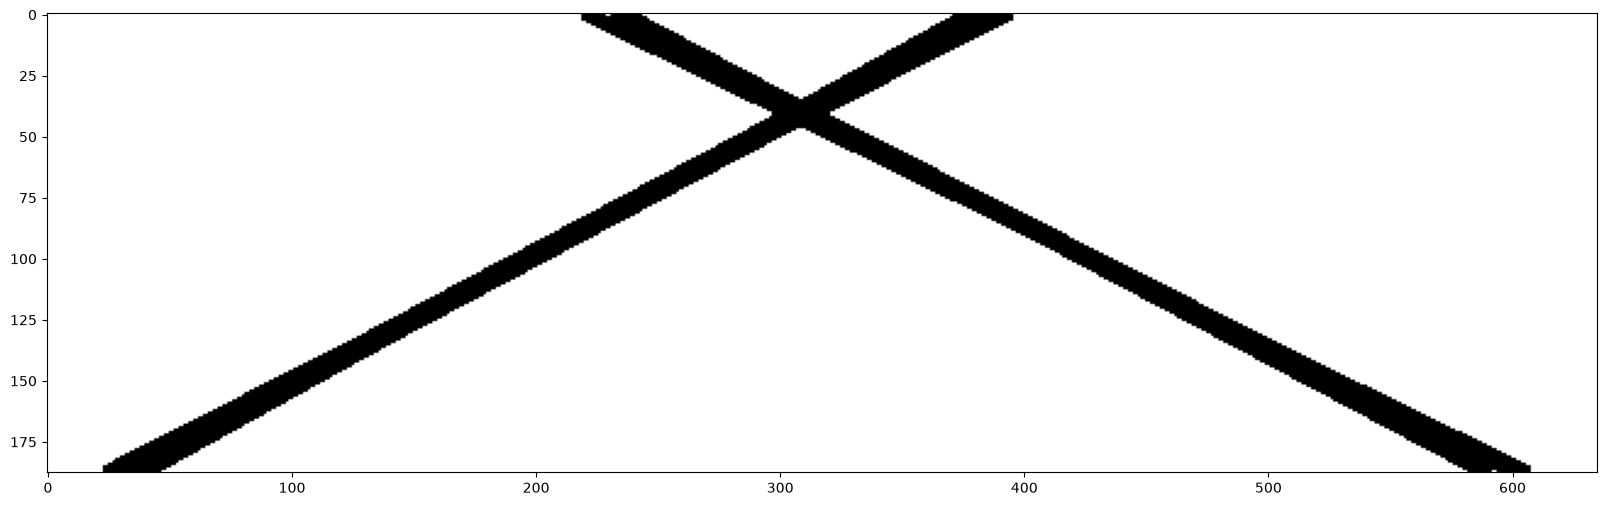

In [12]:
lienzo2 = cv2.erode(lienzo, np.ones((5,5)))
plt.figure(figsize=(20,10))
plt.imshow(lienzo2, cmap="gray")
plt.show()

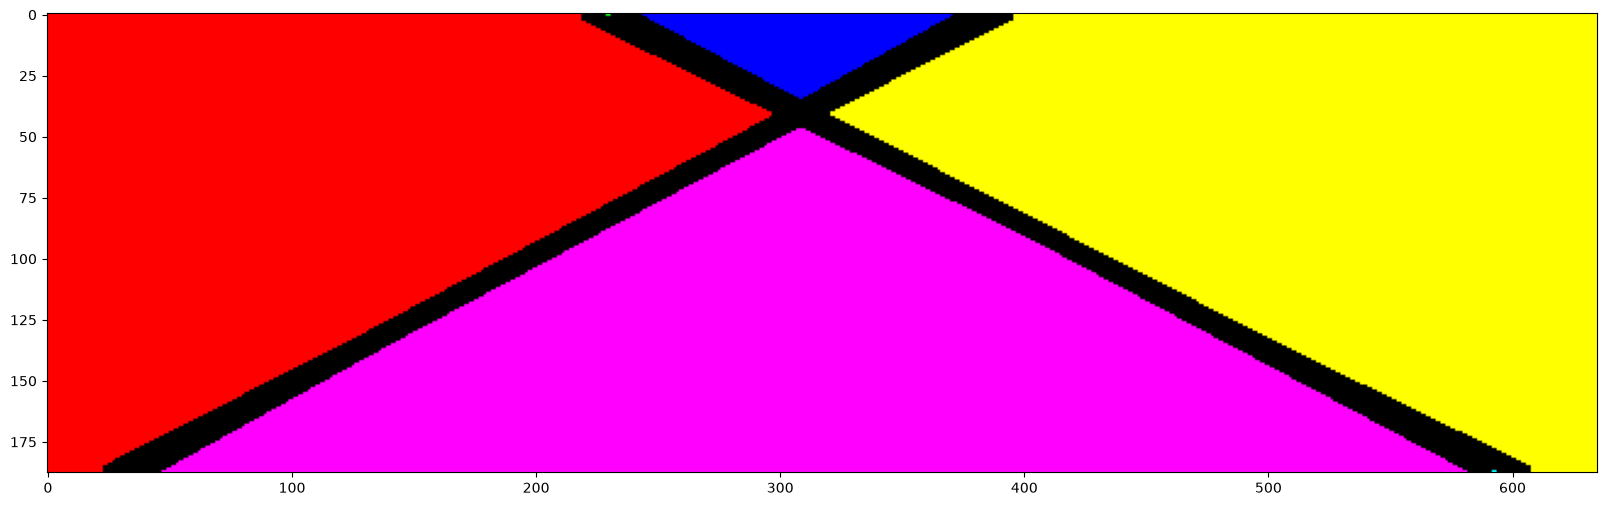

In [13]:
numEtiq ,Ietiq = cv2.connectedComponents(lienzo2)
np.unique(Ietiq)

def funcion_visualiza(I, Ietiq, target, color):
    I = np.asarray(I)
    if I.dtype == bool:
        I = I.astype(np.uint8) * 255

    # Si es gris, la pasamos a 3 canales para poder pintar en color
    if I.ndim == 2:
        Icolor = np.stack([I, I, I], axis=-1).astype(np.uint8)
    else:
        Icolor = I.copy()

    Icolor[Ietiq == target] = color
    return Icolor

Regiones = funcion_visualiza(lienzo2, Ietiq, 1, [255,0,0])
Regiones = funcion_visualiza(Regiones, Ietiq, 2, [0, 255,0])
Regiones = funcion_visualiza(Regiones, Ietiq, 3, [0, 0, 255])
Regiones = funcion_visualiza(Regiones, Ietiq, 4, [255, 255,0])
Regiones = funcion_visualiza(Regiones, Ietiq, 5, [255, 0, 255])
Regiones = funcion_visualiza(Regiones, Ietiq, 6, [0, 255,255])

plt.figure(figsize=(20,10))
plt.imshow(Regiones)
plt.show()

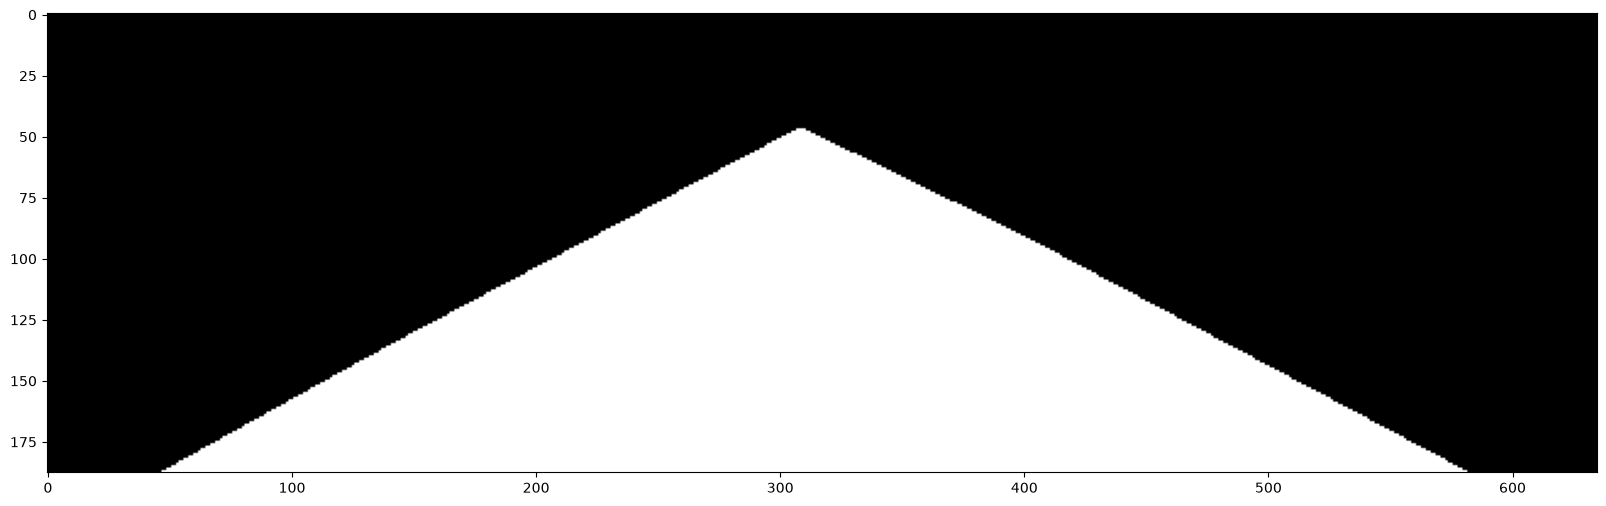

In [14]:
filas, columnas = I.shape

px = columnas // 2
py = filas // 2

etiq = Ietiq[py, px]

lienzo3 = np.zeros((filas, columnas), dtype=np.uint8)
mascara = Ietiq == etiq
lienzo3[mascara] = 255

plt.figure(figsize=(20,10))
plt.imshow(lienzo3, cmap="gray")
plt.show()

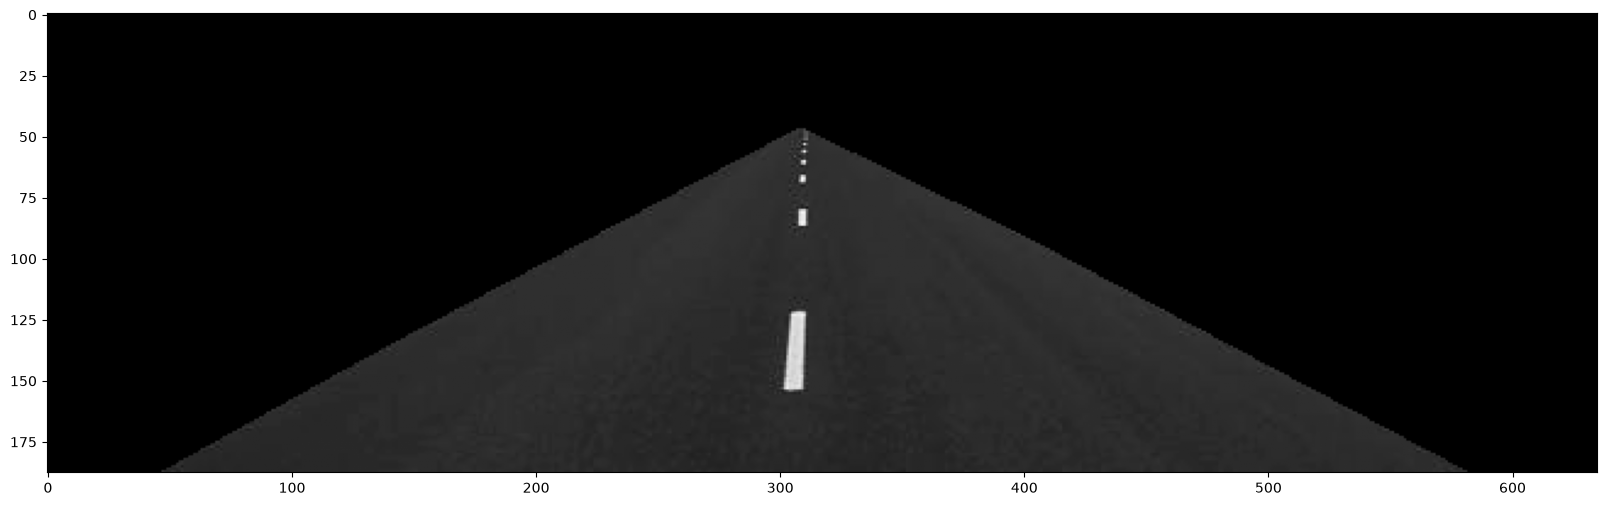

In [15]:
deteccion = I.copy()
deteccion[mascara != 1] = 0

plt.figure(figsize=(20,10))
plt.imshow(deteccion, cmap="gray")
plt.show()

10. Aplica todos los pasos anteriores, con idéntica configuración, para segmentar la imagen

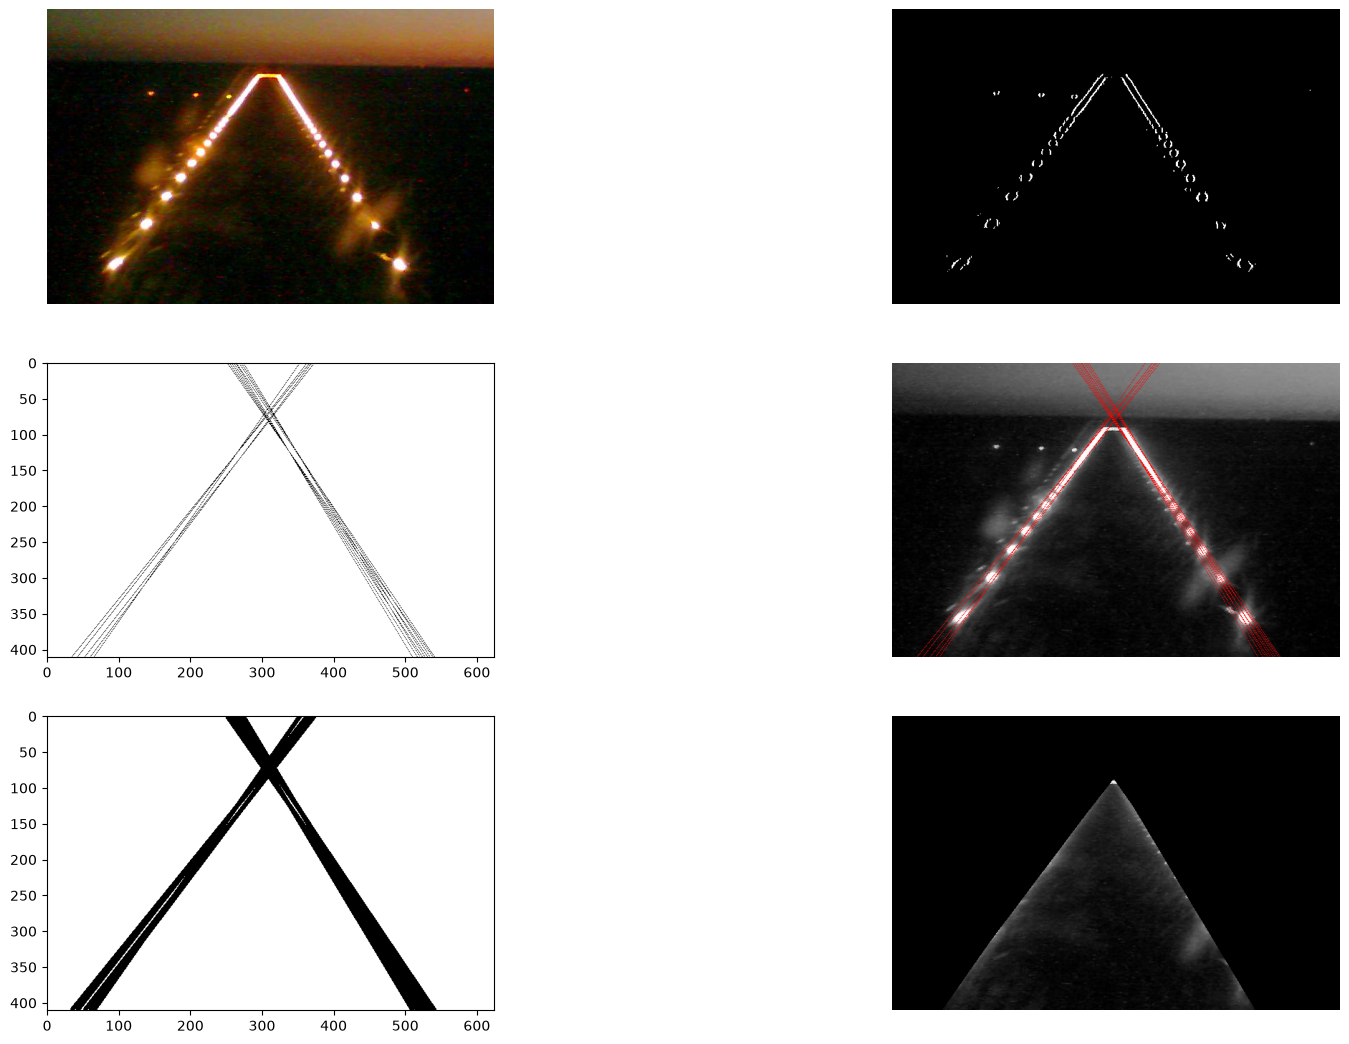

In [16]:
I = cv2.imread("imagenEntrada/PrimeraParte/P7_2.tif")

Icolor = cv2.cvtColor(I, cv2.COLOR_BGR2RGB)

I = cv2.cvtColor(I, cv2.COLOR_BGR2GRAY)

Gx = cv2.Sobel(I, cv2.CV_64F, 1, 0, ksize=3, borderType=cv2.BORDER_REPLICATE)
Gxabs = np.abs(Gx)

maxi = np.max(Gxabs)
umbral = maxi * 0.3

Ib = Gxabs > umbral

P = cv2.HoughLinesWithAccumulator(Ib.astype(np.uint8), 1, np.pi/180, 10)

maxi = np.max(P[:,2])
umbral = 0.5 * maxi

rectas = P[P[:,2] > umbral]

lienzo = np.ones_like(I, dtype=np.uint8) * 255
lienzo2 = np.dstack([I, I, I])

for i in range(len(rectas[:,1])):
    lienzo = generar_lineas_en_imagen(lienzo, np.rad2deg(rectas[i,1]), rectas[i, 0], 0)
    lienzo2 = generar_lineas_en_imagen(lienzo2, np.rad2deg(rectas[i,1]), rectas[i, 0], [255 ,0, 0])

erosion = cv2.erode(lienzo, np.ones((5,5)))

_, Ietiq = cv2.connectedComponents(erosion)

filas, columnas = I.shape

cy = filas // 2
cx = columnas // 2

etiq = Ietiq[cy, cx]

mascara = Ietiq != etiq
segmentada = I.copy()

segmentada[mascara] = 0

plt.figure(figsize=(20,13))
plt.subplot(3,2,1)
plt.imshow(Icolor)
plt.axis("off")

plt.subplot(3,2,2)
plt.imshow(Ib, cmap="gray")
plt.axis("off")

plt.subplot(3,2,3)
plt.imshow(lienzo, cmap="gray")

plt.subplot(3,2,4)
plt.imshow(lienzo2)
plt.axis("off")

plt.subplot(3,2,5)
plt.imshow(erosion, cmap="gray")

plt.subplot(3,2,6)
plt.imshow(segmentada, cmap="gray")
plt.axis("off")

plt.show()


### SEGUNDA PARTE: Segmentación de señales de tráfico mediante la aplicación de la Transformada de Hough para detectar circunferencias.


#### a) Segmentación de señales de limitación de velocidad:

**Lectura de imagen y generación de imagen binaria de interés**

11. A partir de la imagen en color Signal1_1.tif, genera y visualiza una imagen binaria Ib
de puntos "rojos" de la imagen en color, candidatos a pertenecer al contorno de la región
que se pretende segmentar (interior de la señal de tráfico). Para ello, utiliza un método de
umbralización global, tomando como umbrales de referencia para cada componente de
color los siguientes:

```
factor = 0.35;
UmbralRojo = factor*(Rmin+Rmax);
UmbralVerde = factor*(Gmax+Gmin);
UmbralAzul = factor*(Bmax+Bmin); 
```

donde Rmin, Rmax, Gmin, Gmax, Bmin y Bmax, son los valores de intensidad mínimo
y máximo en las componentes roja (R), verde (G) y azul (B) de la imagen en color que está
siendo analizada.



6 255 9 255 6 255


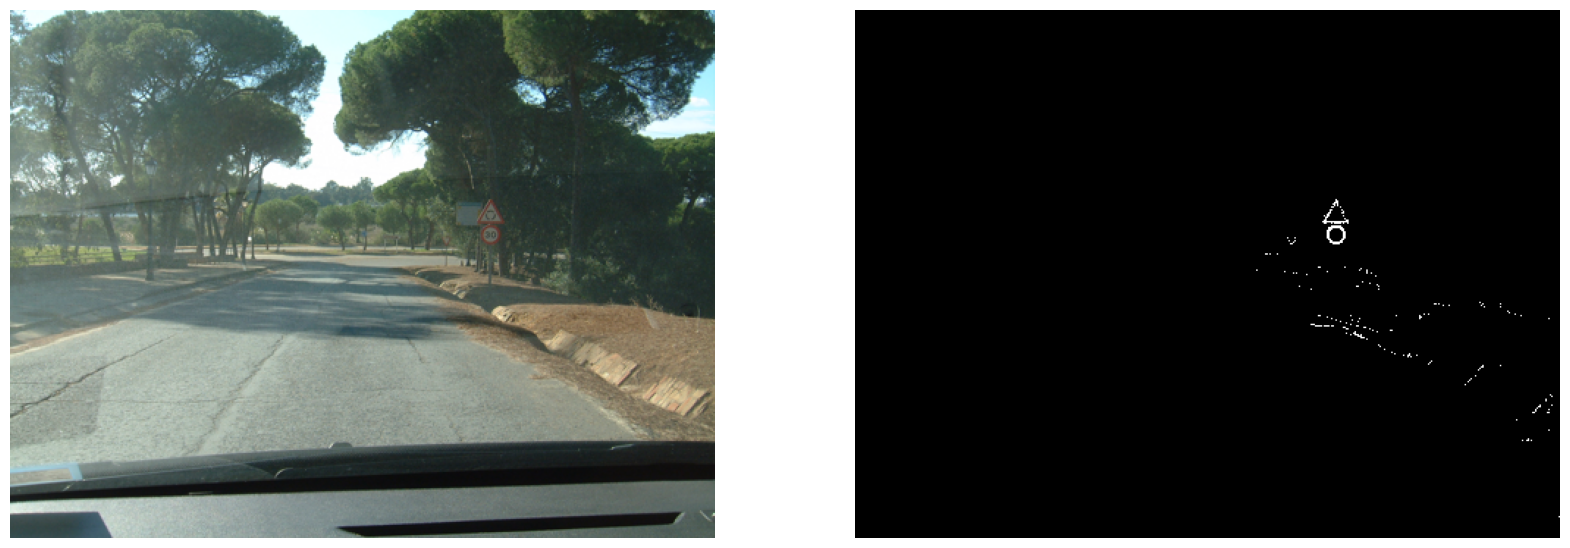

In [18]:
I = cv2.imread("imagenEntrada/SegundaParte/Signal1_1.tif")
I = cv2.cvtColor(I, cv2.COLOR_BGR2RGB)

R = I[:,:,0]
G = I[:,:,1]
B = I[:,:,2]

Rmin = np.min(R)
Rmax = np.max(R)
Bmin = np.min(B)
Bmax = np.max(B)
Gmin = np.min(G)
Gmax = np.max(G)

factor = 0.35
UmbralRojo = factor * (float(Rmin) + float(Rmax))
UmbralVerde = factor * (float(Gmin) + float(Gmax))
UmbralAzul = factor * (float(Bmin) + float(Bmax))

Ib = (R > UmbralRojo) & (G < UmbralVerde) & (B < UmbralAzul)

mascara = Ib.astype(np.uint8) * 255
print(Rmin, Rmax, Gmin, Gmax, Bmin, Bmax)
plt.figure(figsize=(20,10))
plt.subplot(1,2,1)
plt.imshow(I)
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mascara, cmap="gray")
plt.axis("off")
plt.show()

### Transformada Circular de Hough:

12. Aplica la Transformada de Hough para detectar contornos circulares de radios
comprendidos entre 5 y 35. Para ello aplica la función facilitada
generar_acumulador_T_H_Circulos:

r_min = 5; r_max = 35; radios = np.arange(r_min, r_max + 1, 2)

H = generar_acumulador_T_H_Circulos(Ib, radios)

Para entender el procedimiento, se debe tener clara la respuesta a estas preguntas:

− Interpreta las dimensiones de la matriz de salida H. ¿Cuál es el significado de los
valores almacenados en dicha matriz?

− ¿Qué interpretación le das a que el valor de H[146,341,8] sea 23?

− ¿Cuál es la discretización que se realiza del espacio de parámetros?

In [21]:
from Funciones.funciones_Transformada_Hough import generar_acumulador_T_H_Circulos

r_min = 5
r_max = 35
radios = np.arange(r_min, r_max + 1, 2)
H = generar_acumulador_T_H_Circulos(Ib, radios)

print(np.max(H))


24.0
